# OrbitML

Un TLE (Two-Line Element) est une orbite approximative. Propagé avec le modèle SGP4, il prédit la position d'un satellite avec une erreur de l'ordre du kilomètre, et cette erreur grandit. Or cette erreur n'est pas du bruit : elle a une structure. Peng & Bai (2018) proposent de l'apprendre (avec un modèle), puis de la retrancher de la prédiction SGP4.

Pour mesurer l'erreur de SGP4, il faut connaître la vraie position du satellite. On utilise les orbites précises (POE) de Sentinel-6A, calculées par le CNES, avec une précision de l'ordre du centimètre. On a choisi Sentinel-6A parce qu'il fait très peu de manœuvres (4 en 2024).

## Étape 1 : la vérité

Les orbites précises de Sentinel-6A sont dans `data/sp3/s6a/`, au format SP3, un format texte standard. Chaque fichier est compressé en `.Z`. Le module `gzip` de Python ne sait pas le lire, mais la commande `gzip -dc` le décompresse très bien.

Voici à quoi ressemble un fichier une fois décompressé :

```
#cV2023 12 13  3 21  0.00000000   14308 ORBIT ITRF  FIT CNES      <- date de début, 14308 états, repère ITRF
## 2292 271260.00000000    60.00000000 ...                        <- semaine GPS, pas de temps = 60 s
%c L  cc TAI ...                                                  <- échelle de temps : TAI
...
*  2023 12 13  3 21  0.00000000                                   <- une date
PL40  3468.7606188  -817.1050730 -6844.2029489 999999.999999      <- position x, y, z en km
VL40-15613.8151346 65922.4868150-15775.4078392 999999.999999      <- vitesse vx, vy, vz en dm/s
*  2023 12 13  3 22  0.00000000
...
```

Quelques remarques :

- Le repère est l'ITRF, un repère qui tourne avec la Terre. SGP4, lui, donne des positions dans TEME. Il faudra convertir l'un dans l'autre
- Les dates sont en TAI, pas en UTC.
- Les vitesses sont en dm/s. On les divise par 10⁴ pour avoir des km/s.
- Un fichier couvre environ 10 jours, avec un état par minute.

In [1]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.coordinates import ITRS, TEME, CartesianRepresentation
from astropy.time import Time
from sgp4.api import Satrec

On lit un seul fichier pour commencer. Pour chaque date (ligne `*`), on garde la position (ligne `P`) et la vitesse (ligne `V`).

In [2]:
path = Path("data/sp3/s6a/ssas6a30.b24001.e24011.DG_.sp3.001.Z")
lines = subprocess.run(["gzip", "-dc", path], capture_output=True, text=True, check=True).stdout.splitlines()

dates, r, v = [], [], []
for line in lines:
    if line.startswith("*"):
        # "*  2023 12 13  3 21  0.00000000" -> année, mois, jour, heure, minute, seconde
        dates.append([float(x) for x in line[1:].split()])
    elif line.startswith("P"):
        r.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])
    elif line.startswith("V"):
        v.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])

dates = np.array(dates)
year, month, day, hour, minute = dates[:, :5].astype(int).T  # astropy veut des entiers ici
time = Time(
    {"year": year, "month": month, "day": day, "hour": hour, "minute": minute, "second": dates[:, 5]},
    format="ymdhms", scale="tai",
)
r = np.array(r)          # km, ITRF
v = np.array(v) / 1e4    # dm/s -> km/s, ITRF

print(len(time), "états, de", time[0].utc.iso, "à", time[-1].utc.iso, "UTC")
print("pas de temps :", np.unique(np.diff(time.unix)), "s")
print("r :", r.shape, " v :", v.shape)

14308 états, de 2024-01-01 23:17:23.000 à 2024-01-11 21:44:23.000 UTC
pas de temps : [60.] s
r : (14308, 3)  v : (14308, 3)


La distance au centre de la Terre moins le rayon terrestre (6378 km à l'équateur) doit redonner l'altitude annoncée de Sentinel-6A, environ 1336 km.

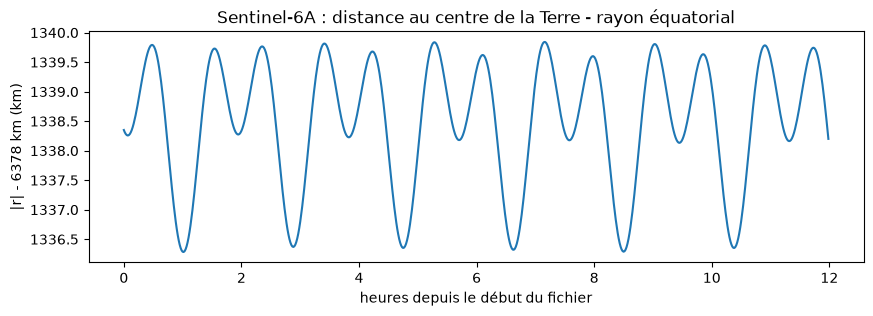

|r| - 6378 km : de 1336.2 à 1339.9 km sur tout le fichier


In [3]:
EARTH_RADIUS = 6378.137  # km, rayon équatorial

distance = np.linalg.norm(r, axis=1)
hours = (time - time[0]).to_value("hour")
first = hours < 12

plt.figure(figsize=(10, 3))
plt.plot(hours[first], distance[first] - EARTH_RADIUS)
plt.xlabel("heures depuis le début du fichier")
plt.ylabel("|r| - 6378 km (km)")
plt.title("Sentinel-6A : distance au centre de la Terre - rayon équatorial")
plt.show()

print(f"|r| - 6378 km : de {distance.min() - EARTH_RADIUS:.1f} à {distance.max() - EARTH_RADIUS:.1f} km sur tout le fichier")

On retrouve environ 1338 km, et la distance au centre ne varie que de ±2 km : l'orbite est presque circulaire.

Attention, cette courbe montre le rayon de l'orbite et non l'altitude au-dessus du sol. La Terre est aplatie (le rayon polaire fait 21 km de moins que le rayon équatorial), donc l'altitude réelle varie beaucoup plus que ces ±2 km.

On trace les 6 premières heures, soit environ 3 révolutions.

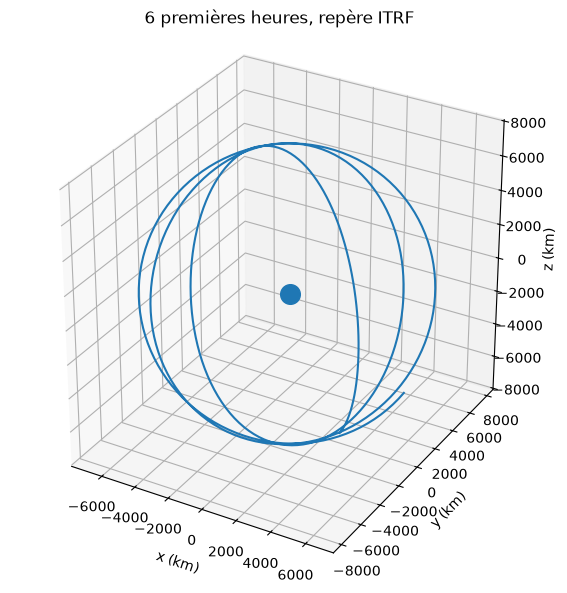

In [4]:
first = hours < 6

ax = plt.figure(figsize=(7, 7)).add_subplot(projection="3d")
ax.plot(*r[first].T)
ax.scatter(0, 0, 0, color="tab:blue", s=200)  # la Terre, pas à l'échelle
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km)")
ax.set_aspect("equal")
ax.set_title("6 premières heures, repère ITRF")
plt.show()

L'orbite ne se referme pas : chaque révolution est décalée par rapport à la précédente. Ce n'est pas le satellite qui dérive, c'est le repère : l'ITRF tourne avec la Terre, d'environ 28° pendant une révolution.

## Étape 2 : SGP4

Les TLE de Sentinel-6A sont dans `data/tle/`. On n'en a qu'à partir de 2024, c'est pour ça qu'on lit le fichier SP3 du 1er janvier 2024 à l'étape 1. Un TLE tient sur deux lignes :

```
1 46984U 20086A   24001.60261332 -.00000054  00000-0  31477-4 0  9993     <- date du TLE : 2024, jour 1.6026
2 46984  66.0389 199.3442 0007637 269.6041  90.4099 12.80929714145361     <- inclinaison, nœud, excentricité 0.0007637, ..., 12.8 révolutions par jour
```

Pour l'instant, on prend juste le premier TLE du fichier.

In [5]:
tle = Path("data/tle/46984_2024-01-01_2025-01-02.tle").read_text().splitlines()
satellite = Satrec.twoline2rv(tle[0], tle[1])
tle_date = Time(satellite.jdsatepoch, satellite.jdsatepochF, format="jd", scale="utc")

print("date du TLE :", tle_date.iso, "UTC")

date du TLE : 2024-01-01 14:27:45.791 UTC


SGP4 donne la position en TEME, en km, aux dates qu'on lui demande (en UTC). On lui demande les dates du SP3, à partir de la date du TLE.

In [6]:
after = time >= tle_date
error, r_sgp4, v_sgp4 = satellite.sgp4_array(time[after].utc.jd1, time[after].utc.jd2)

print("codes d'erreur :", np.unique(error))  # 0 = tout va bien
print("r_sgp4 :", r_sgp4.shape)

codes d'erreur : [0]
r_sgp4 : (14308, 3)


Pour comparer, on passe la vérité de l'ITRF au TEME avec astropy.

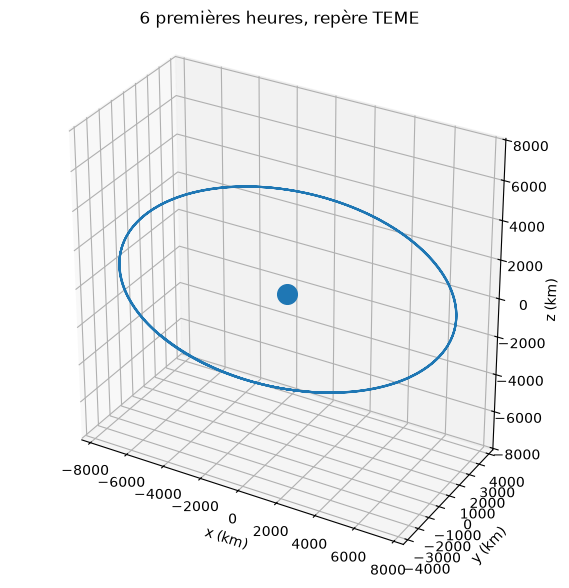

In [7]:
itrs = ITRS(CartesianRepresentation(r[after].T * u.km), obstime=time[after])
r_true = itrs.transform_to(TEME(obstime=time[after])).cartesian.xyz.to_value(u.km).T

ax = plt.figure(figsize=(7, 7)).add_subplot(projection="3d")
ax.plot(*r_true[:360].T)  # 360 états de 60 s = 6 h
ax.scatter(0, 0, 0, color="tab:blue", s=200)
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km)")
ax.set_aspect("equal")
ax.set_title("6 premières heures, repère TEME")
plt.show()

Cette fois, l'orbite se referme : TEME ne tourne pas avec la Terre. Les deux positions sont maintenant dans le même repère, on peut regarder la distance entre elles.

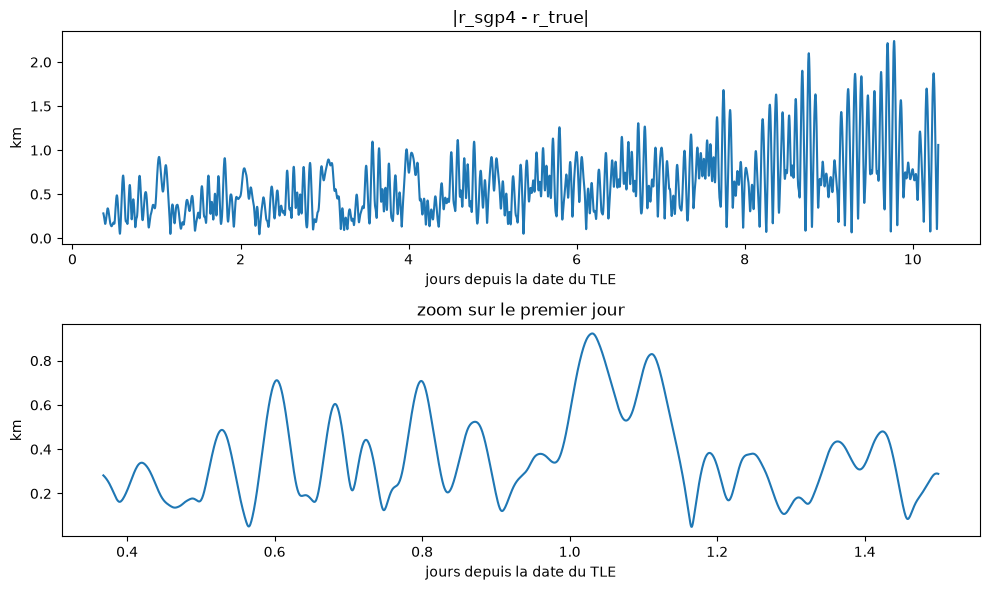

In [8]:
days = (time[after] - tle_date).to_value("day")
distance = np.linalg.norm(r_sgp4 - r_true, axis=1)
first = days < 1.5

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6))
top.plot(days, distance)
top.set_title("|r_sgp4 - r_true|")
bottom.plot(days[first], distance[first])
bottom.set_title("zoom sur le premier jour")
for ax in (top, bottom):
    ax.set_xlabel("jours depuis la date du TLE")
    ax.set_ylabel("km")
fig.tight_layout()
plt.show()

L'erreur part d'environ 300 m et monte jusqu'à environ 2 km au bout de 10 jours. Elle n'est pas aléatoire : elle oscille au rythme des révolutions et son amplitude grandit. C'est cette structure qu'on voudra apprendre.

## Étape 3 : l'erreur dans le repère RSW

La norme ne dit pas dans quelle direction SGP4 se trompe. On projette donc l'erreur $e = r_{sgp4} - r_{true}$ sur trois directions liées au satellite :

- R (radial) : de la Terre vers le satellite, $R = \dfrac{r}{|r|}$
- W (perpendiculaire au plan de l'orbite) : $W = \dfrac{r \times v}{|r \times v|}$
- S (le long de la trajectoire) : $S = W \times R$, presque dans le sens de la vitesse

On construit ce repère à partir de la position et de la vitesse SGP4, pas de la "vérité". Le but est de corriger une prédiction, et au moment de prédire on ne connaît que SGP4.

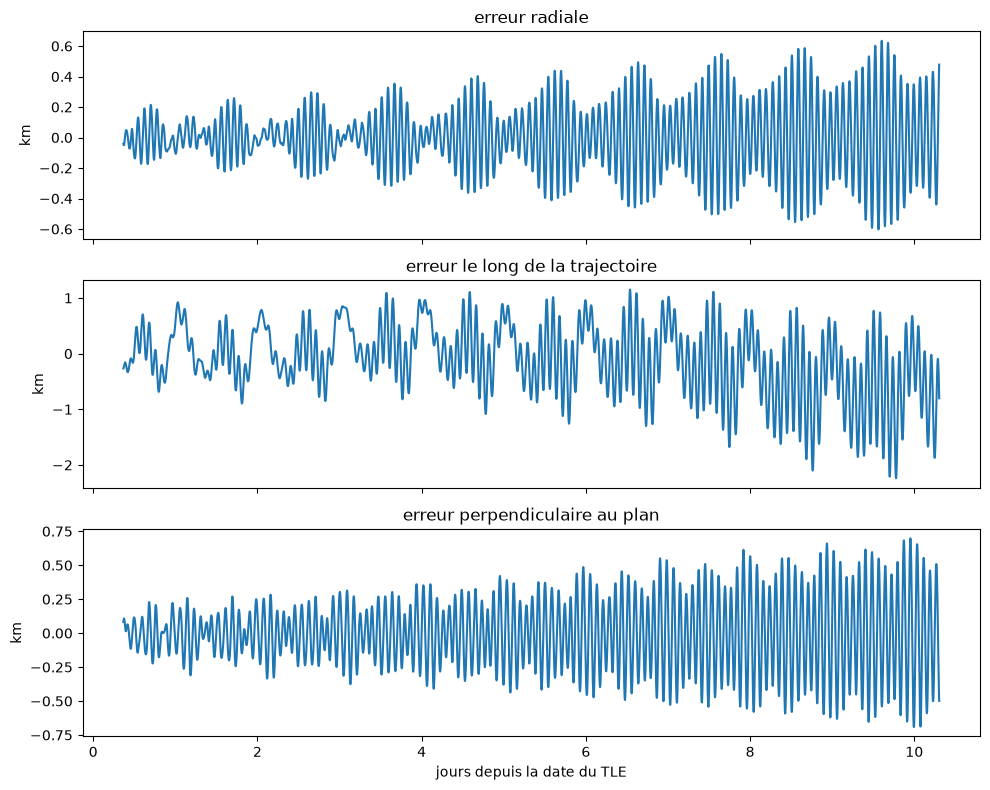

R : de -0.60 à 0.63 km
S : de -2.24 à 1.15 km
W : de -0.69 à 0.70 km


In [9]:
e = r_sgp4 - r_true

R = r_sgp4 / np.linalg.norm(r_sgp4, axis=1, keepdims=True)
W = np.cross(r_sgp4, v_sgp4)
W = W / np.linalg.norm(W, axis=1, keepdims=True)
S = np.cross(W, R)

# produit scalaire ligne par ligne : la composante de e selon chaque direction
e_r = np.sum(e * R, axis=1)
e_s = np.sum(e * S, axis=1)
e_w = np.sum(e * W, axis=1)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, component, name in zip(axes, (e_r, e_s, e_w), ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.plot(days, component)
    ax.set_title(f"erreur {name}")
    ax.set_ylabel("km")
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

for component, name in zip((e_r, e_s, e_w), ("R", "S", "W")):
    print(f"{name} : de {component.min():.2f} à {component.max():.2f} km")

Les trois composantes oscillent une fois par révolution, avec une amplitude qui grandit au fil des jours. En R et en W, elles restent centrées sur zéro et dépassent à peine 600 m.

L'erreur le long de la trajectoire (S) est la plus grande. En plus de son oscillation, sa moyenne se décale : proche de zéro les premiers jours, elle descend à environ −600 m le dernier jour. SGP4 place alors le satellite, en moyenne, 600 m derrière sa vraie position. C'est typique de l'erreur le long de la trajectoire : une petite erreur sur la vitesse moyenne du satellite s'accumule à chaque révolution.

## Étape 4 : plusieurs TLE

Jusqu'ici, on n'a regardé qu'un seul TLE. Avant de chercher à corriger l'erreur, il faut savoir si elle a la même forme d'un TLE à l'autre.

In [10]:
itrs = ITRS(CartesianRepresentation(r.T * u.km), obstime=time)
r_true_full = itrs.transform_to(TEME(obstime=time)).cartesian.xyz.to_value(u.km).T


def rsw_error(satellite, time, r_true):
    # étape 2 : propager à partir de la date du TLE
    tle_date = Time(satellite.jdsatepoch, satellite.jdsatepochF, format="jd", scale="utc")
    after = time >= tle_date
    _, r_sgp4, v_sgp4 = satellite.sgp4_array(time[after].utc.jd1, time[after].utc.jd2)
    e = r_sgp4 - r_true[after]

    # étape 3 : projeter sur R, S, W
    R = r_sgp4 / np.linalg.norm(r_sgp4, axis=1, keepdims=True)
    W = np.cross(r_sgp4, v_sgp4)
    W = W / np.linalg.norm(W, axis=1, keepdims=True)
    S = np.cross(W, R)

    days = (time[after] - tle_date).to_value("day")
    return days, np.sum(e * R, axis=1), np.sum(e * S, axis=1), np.sum(e * W, axis=1)

On prend tous les TLE publiés pendant les 3 premiers jours du fichier SP3, pour que chacun soit propagé au moins 7 jours. Le fichier de TLE contient des doublons (105 sur 909 : même date, mêmes valeurs), on les saute.

In [11]:
satellites, seen = [], set()
for line1, line2 in zip(tle[0::2], tle[1::2]):
    sat = Satrec.twoline2rv(line1, line2)
    if Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc") > time[0] + 3 * u.day:
        break  # le fichier est trié par date
    if line1[18:32] in seen:  # colonnes de la date du TLE
        continue
    seen.add(line1[18:32])
    satellites.append(sat)

print(len(satellites), "TLE")

10 TLE


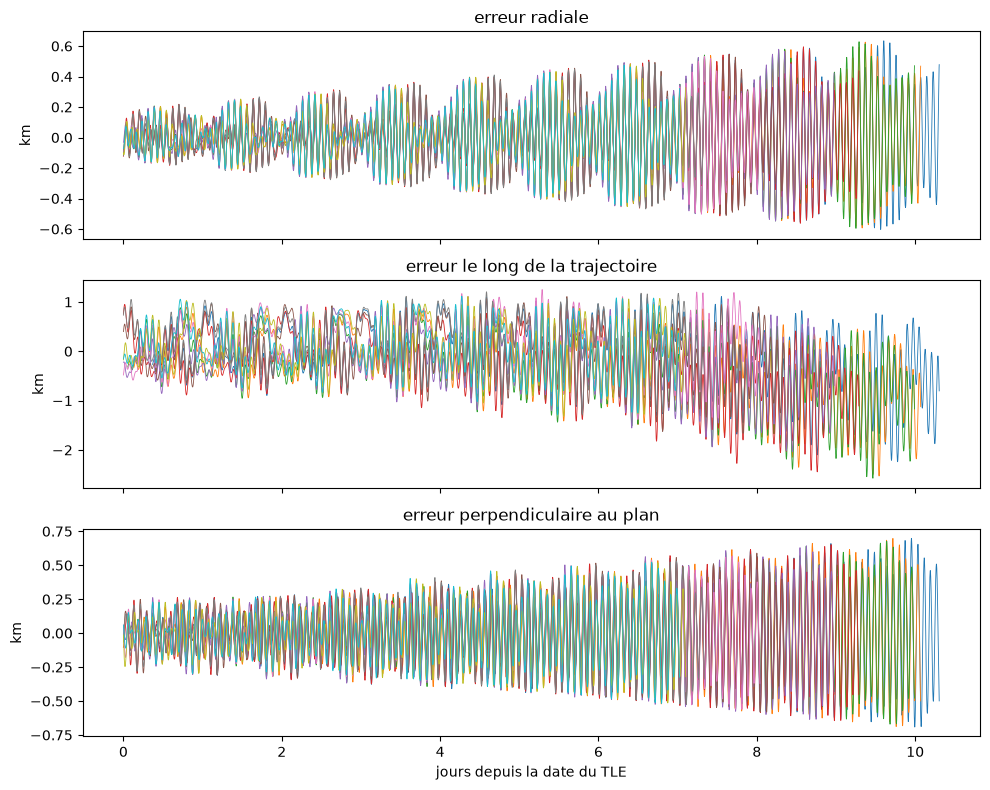

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for sat in satellites:
    days, e_r, e_s, e_w = rsw_error(sat, time, r_true_full)
    for ax, component in zip(axes, (e_r, e_s, e_w)):
        ax.plot(days, component, linewidth=0.6)

for ax, name in zip(axes, ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.set_title(f"erreur {name}")
    ax.set_ylabel("km")
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

En R et en W, les courbes des 10 TLE se superposent presque : même oscillation, même croissance. Au bout de 6 à 7 jours, l'amplitude vaut environ 500 m pour tous les TLE. Cette partie de l'erreur dépend surtout du temps écoulé depuis la date du TLE.

En S, les courbes sont dispersées dès le départ (entre −0,5 et +1 km), et la moyenne dérive différemment selon le TLE : entre −400 m et 0 entre le 6e et le 7e jour, et jusqu'à −1 km à 10 jours pour les premiers TLE. Cette dérive est propre à chaque TLE. C'est la partie la plus difficile à prévoir.

## Étape 5 : première correction

En R et en W, l'erreur a presque la même forme pour tous les TLE. L'idée la plus simple est de prendre la moyenne des erreurs des 10 TLE, en fonction du temps écoulé depuis la date du TLE, et de la retrancher à SGP4.

Pour savoir si ça marche, il faut tester la correction sur d'autres TLE que ceux qui ont servi à la calculer. Sinon, on mesure seulement à quel point la moyenne ressemble aux données qui l'ont construite. On prend donc le fichier SP3 suivant (du 11 au 21 janvier) et les TLE publiés pendant ses 3 premiers jours.

In [13]:
def read_sp3(path):
    lines = subprocess.run(["gzip", "-dc", path], capture_output=True, text=True, check=True).stdout.splitlines()

    dates, r = [], []
    for line in lines:
        if line.startswith("*"):
            dates.append([float(x) for x in line[1:].split()])
        elif line.startswith("P"):
            r.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])

    dates = np.array(dates)
    year, month, day, hour, minute = dates[:, :5].astype(int).T
    time = Time(
        {"year": year, "month": month, "day": day, "hour": hour, "minute": minute, "second": dates[:, 5]},
        format="ymdhms", scale="tai",
    )
    itrs = ITRS(CartesianRepresentation(np.array(r).T * u.km), obstime=time)
    return time, itrs.transform_to(TEME(obstime=time)).cartesian.xyz.to_value(u.km).T


test_time, test_r_true = read_sp3(Path("data/sp3/s6a/ssas6a30.b24011.e24021.DG_.sp3.001.Z"))

test_satellites, seen = [], set()
for line1, line2 in zip(tle[0::2], tle[1::2]):
    sat = Satrec.twoline2rv(line1, line2)
    date = Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc")
    if date < test_time[0] or line1[18:32] in seen:
        continue
    if date > test_time[0] + 3 * u.day:
        break
    seen.add(line1[18:32])
    test_satellites.append(sat)

print(len(test_satellites), "TLE de test, à partir du", test_time[0].utc.iso)

6 TLE de test, à partir du 2024-01-11 21:16:23.000


Les TLE ne tombent pas tous au même moment par rapport aux dates du SP3. Pour faire la moyenne, on ramène donc chaque courbe sur une même grille : une valeur par minute, de 0 à 7 jours après la date du TLE. C'est `np.interp` qui fait l'interpolation linéaire.

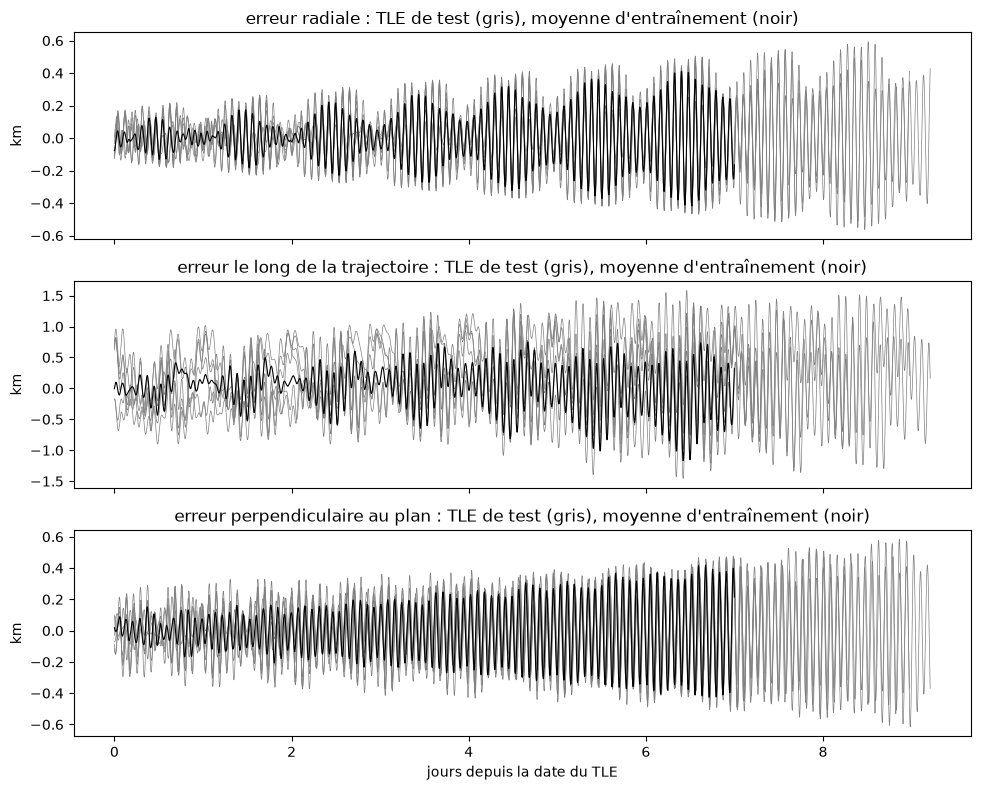

In [14]:
grid = np.arange(0, 7, 1 / 1440)  # en jours, 1440 minutes par jour

curves = []
for sat in satellites:
    days, e_r, e_s, e_w = rsw_error(sat, time, r_true_full)
    curves.append([np.interp(grid, days, component) for component in (e_r, e_s, e_w)])
mean_error = np.mean(curves, axis=0)  # (3, len(grid)) : R, S, W

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for sat in test_satellites:
    days, e_r, e_s, e_w = rsw_error(sat, test_time, test_r_true)
    for ax, component in zip(axes, (e_r, e_s, e_w)):
        ax.plot(days, component, color="gray", linewidth=0.5)
for ax, mean, name in zip(axes, mean_error, ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.plot(grid, mean, color="black", linewidth=0.8)
    ax.set_title(f"erreur {name} : TLE de test (gris), moyenne d'entraînement (noir)")
    ax.set_ylabel("km")
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

La moyenne garde les oscillations : elles sont en phase d'un TLE à l'autre, donc elles ne s'annulent pas.

Pour comparer, on essaie aussi une correction encore plus simple : un polynôme de degré 2 en fonction du temps, ajusté sur la courbe moyenne.

On mesure chaque correction par la RMS (racine de la moyenne des carrés) de l'erreur qui reste, sur les 7 premiers jours de chaque TLE de test.

In [15]:
polynomials = [np.polyfit(grid, mean, 2) for mean in mean_error]

residuals = {"sans correction": [], "courbe moyenne": [], "polynôme": []}
for sat in test_satellites:
    days, e_r, e_s, e_w = rsw_error(sat, test_time, test_r_true)
    keep = days < 7
    e = np.array([e_r, e_s, e_w])[:, keep]
    residuals["sans correction"].append(e)
    residuals["courbe moyenne"].append(e - np.array([np.interp(days[keep], grid, mean) for mean in mean_error]))
    residuals["polynôme"].append(e - np.array([np.polyval(p, days[keep]) for p in polynomials]))

for name, residual in residuals.items():
    residual = np.concatenate(residual, axis=1)
    rms = np.sqrt(np.mean(residual**2, axis=1))
    total = np.sqrt(np.mean(np.sum(residual**2, axis=0)))
    print(f"{name:16}  R {rms[0]:.3f}   S {rms[1]:.3f}   W {rms[2]:.3f}   total {total:.3f} km")

sans correction   R 0.166   S 0.529   W 0.190   total 0.587 km
courbe moyenne    R 0.077   S 0.455   W 0.133   total 0.480 km
polynôme          R 0.166   S 0.530   W 0.190   total 0.587 km


La courbe moyenne réduit l'erreur sur des TLE qu'elle n'a jamais vus : de moitié en R, d'un tiers en W, mais seulement de 14 % en S. Au total, on passe de 587 m à 480 m. En S, elle ne peut pas prévoir la dérive, qui change d'un TLE à l'autre.

Le polynôme, lui, ne fait rien. L'erreur est surtout une oscillation à chaque révolution, et un polynôme de degré 2 ne peut pas la suivre : il ne trouve qu'une tendance, et la tendance moyenne est presque nulle.

Il faut rester prudent : on n'a testé que 6 TLE, sur une seule semaine.

## Étape 6 : toute l'année 2024

6 TLE de test, c'est trop peu pour conclure. On refait l'étape 5 sur tous les fichiers SP3 de 2024.

On saute les 4 fichiers qui contiennent une manœuvre (29 février, 28 mai, 17 septembre, 12 décembre) : pendant une poussée, SGP4 ne peut pas suivre le satellite. On saute aussi les TLE publiés dans les 5 jours qui suivent une manœuvre. Un TLE est ajusté sur plusieurs jours d'observations, donc juste après une poussée il mélange l'orbite d'avant et celle d'après.

On sépare l'entraînement et le test dans le temps : premier semestre pour l'entraînement, à partir du 11 juillet pour le test. Les 10 jours d'écart évitent que des TLE presque identiques se retrouvent des deux côtés.

In [16]:
burns = Time(["2024-02-29", "2024-05-28", "2024-09-17", "2024-12-12"], scale="utc")


def tles_after(start):
    # les TLE publiés pendant les 3 jours qui suivent start, sans doublons
    satellites, seen = [], set()
    for line1, line2 in zip(tle[0::2], tle[1::2]):
        sat = Satrec.twoline2rv(line1, line2)
        date = Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc")
        if date < start or line1[18:32] in seen:
            continue
        if date > start + 3 * u.day:
            break
        seen.add(line1[18:32])
        satellites.append(sat)
    return satellites


errors, tle_dates = [], []
for path in sorted(Path("data/sp3/s6a").glob("*.Z")):
    file_time, file_r_true = read_sp3(path)
    if any((file_time[0] <= burn) & (burn <= file_time[-1]) for burn in burns):
        print("manœuvre, on saute", path.name)
        continue
    for sat in tles_after(file_time[0]):
        tle_date = Time(sat.jdsatepoch, sat.jdsatepochF, format="jd", scale="utc")
        if any((burn <= tle_date) & (tle_date < burn + 5 * u.day) for burn in burns):
            continue  # juste après une manœuvre
        days, e_r, e_s, e_w = rsw_error(sat, file_time, file_r_true)
        if days[-1] < 7:  # certains fichiers font 9 jours : pas assez de vérité après ce TLE
            continue
        errors.append([np.interp(grid, days, component) for component in (e_r, e_s, e_w)])
        tle_dates.append(tle_date)

errors = np.array(errors)  # (nombre de TLE, 3, len(grid))
tle_dates = Time(tle_dates)
train = tle_dates < Time("2024-07-01")
test = tle_dates >= Time("2024-07-11")

print(errors.shape)
print(train.sum(), "TLE d'entraînement,", test.sum(), "TLE de test")

manœuvre, on saute ssas6a30.b24051.e24061.DG_.sp3.001.Z


manœuvre, on saute ssas6a30.b24140.e24150.DG_.sp3.001.Z


manœuvre, on saute ssas6a30.b24259.e24269.DG_.sp3.001.Z


manœuvre, on saute ssas6a30.b24339.e24349.DG_.sp3.001.Z


(185, 3, 10080)
92 TLE d'entraînement, 87 TLE de test


Toutes les erreurs sont maintenant sur la même grille, donc la correction et l'évaluation tiennent en quelques lignes.

sans correction   R 0.159   S 0.507   W 0.269   total 0.595 km
courbe moyenne    R 0.083   S 0.424   W 0.130   total 0.451 km


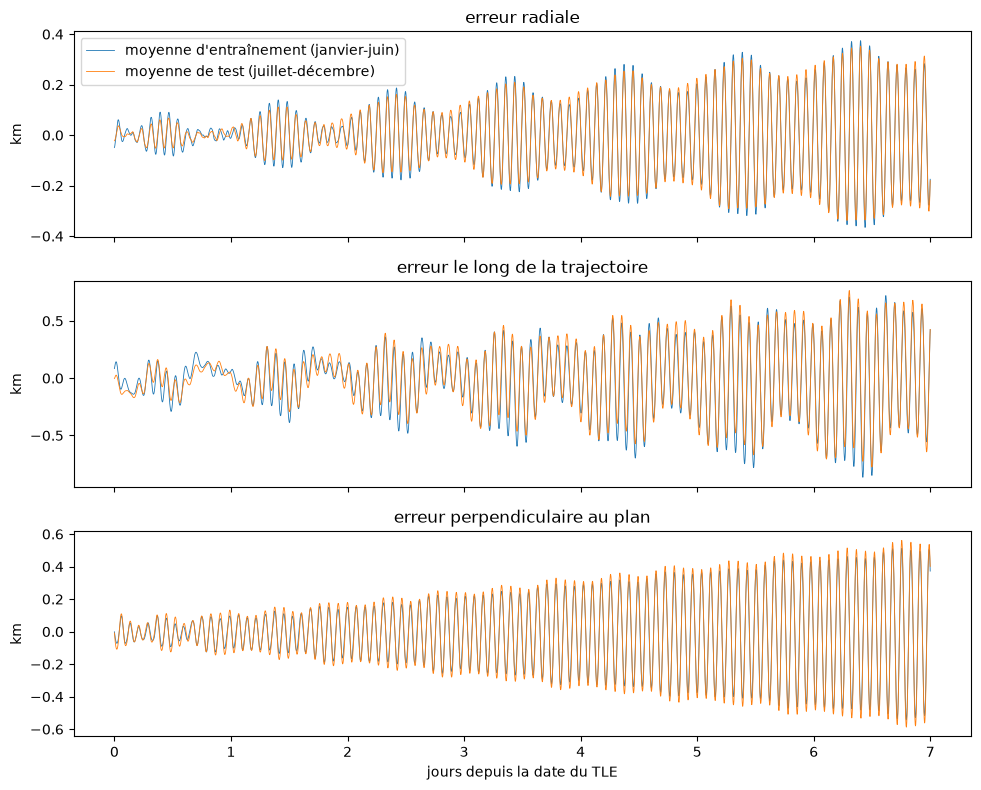

In [17]:
mean_error = errors[train].mean(axis=0)

for name, residual in (("sans correction", errors[test]), ("courbe moyenne", errors[test] - mean_error)):
    rms = np.sqrt(np.mean(residual**2, axis=(0, 2)))
    total = np.sqrt(np.mean(np.sum(residual**2, axis=1)))
    print(f"{name:16}  R {rms[0]:.3f}   S {rms[1]:.3f}   W {rms[2]:.3f}   total {total:.3f} km")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, k, name in zip(axes, range(3), ("radiale", "le long de la trajectoire", "perpendiculaire au plan")):
    ax.plot(grid, mean_error[k], linewidth=0.6, label="moyenne d'entraînement (janvier-juin)")
    ax.plot(grid, errors[test].mean(axis=0)[k], linewidth=0.6, label="moyenne de test (juillet-décembre)")
    ax.set_title(f"erreur {name}")
    ax.set_ylabel("km")
axes[0].legend()
axes[-1].set_xlabel("jours depuis la date du TLE")
fig.tight_layout()
plt.show()

Le résultat de l'étape 5 tient sur toute l'année : la courbe moyenne divise l'erreur par deux en R et en W, mais ne gagne que 16 % en S. Au total, l'erreur passe de 595 m à 451 m.

Les deux moyennes, l'une calculée sur janvier-juin et l'autre sur juillet-décembre, se superposent presque, y compris en S. La partie systématique de l'erreur ne change donc pas au cours de l'année. Ce qui reste en S, c'est la partie propre à chaque TLE, qui se moyenne à zéro.

Pour voir comment ça varie d'un TLE à l'autre, on calcule la RMS de chaque TLE séparément.

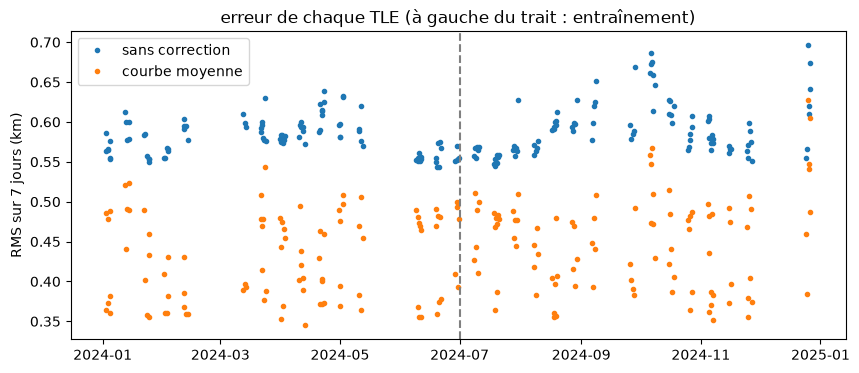

In [18]:
rms_none = np.sqrt(np.mean(np.sum(errors**2, axis=1), axis=1))
rms_mean = np.sqrt(np.mean(np.sum((errors - mean_error) ** 2, axis=1), axis=1))

plt.figure(figsize=(10, 4))
plt.plot(tle_dates.datetime64, rms_none, ".", label="sans correction")
plt.plot(tle_dates.datetime64, rms_mean, ".", label="courbe moyenne")
plt.axvline(np.datetime64("2024-07-01"), color="gray", linestyle="--")
plt.ylabel("RMS sur 7 jours (km)")
plt.title("erreur de chaque TLE (à gauche du trait : entraînement)")
plt.legend()
plt.show()

Sans correction, l'erreur est très régulière : entre 550 et 650 m pour 9 TLE sur 10. La correction fait mieux pour chaque TLE, et les TLE corrigés semblent se répartir en deux groupes, vers 370 m et vers 480 m. On ne sait pas encore pourquoi, et l'heure de publication du TLE ne l'explique pas.